# Assignment 5 - ANOVA and Simple Linear Regression

Group members: Sebastian Bartko, Mariia Moskovko, Matej Palas, Sebastian Halas

Table of contents
1. Part 1 - Composite strength across curing methods
2. Part 2 - Diagnostics, post-hoc comparisons, and magnitude
3. Part 3 - Pump flow and energy use
4. Part 4 - Regression diagnostics and prediction
5. Part 5 - AI-use and conclusion

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import probplot, pearsonr
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.oneway import anova_oneway

In [3]:
strengths = pd.read_csv("data/assignment05_composite_strength.csv")
pump = pd.read_csv("data/assignment05_pump_energy.csv")

display(strengths.head())
display(strengths["curing_method"].unique())
display(pump.head())

,specimen_id,curing_method,strength_mpa
0,1,ambient,53.09
1,2,ambient,48.91
2,3,ambient,55.11
3,4,ambient,54.53
4,5,ambient,57.05


<StringArray>
['ambient', 'thermal', 'uv', 'hybrid']
Length: 4, dtype: str

,run_id,flow_l_min,energy_kwh
0,1,22.70,18.110
1,2,22.93,13.534
2,3,23.42,15.300
3,4,24.35,17.677
4,5,25.13,18.420


# Part 1 - Composite strength across curing methods

The file contains independent composite specimens cured by four methods. The response is `strength_mpa` and the factor is `curing_method`.

**a.** Identify the population, observational unit, response, factor, and factor levels. Explain what additional design information would be needed for a causal claim about curing method.

- **Population:** all composite specimens of this kind that could be made and cured with one of the four methods. We only have a sample of 96 of them.
- **Observational unit:** one specimen. Each row in the data is one specimen.
- **Response:** `strength_mpa`, how strong the specimen is, in MPa. This is what we measure.
- **Factor:** `curing_method`, the way the specimen was cured (hardened). This is what we think might change the strength.
- **Factor levels:** the four methods: ambient, thermal, uv and hybrid.

**Can we say the method causes the strength difference?** Not from the data alone. We would need to know how the study was done:
- Was it random which specimen got which method? If for example all hybrid specimens came from a better batch of material, the batch could be the real reason.
- Were all specimens made from the same material, with the same size, and tested on the same machine?
- Were the specimens tested in a random order, so that things like machine wear do not affect one group more than another?
- Was each specimen cured on its own, and not several together in one oven run?

Only if the answer to these is yes can we put a difference in strength down to the curing method.

**b.** Report group sample sizes, means, and sample standard deviations. Create side-by-side boxplots and describe between-group differences and within-group variation.

In [4]:
order = ["ambient", "thermal", "uv", "hybrid"]
summary = strengths.groupby("curing_method")["strength_mpa"].agg(["count", "mean", "std"]).loc[order]
summary.columns = ["n", "mean (MPa)", "sd (MPa)"]
display(summary.round(2))
print(f"largest sd / smallest sd = {summary['sd (MPa)'].max() / summary['sd (MPa)'].min():.2f}")

,n,mean (MPa),sd (MPa)
curing_method,,,
ambient,24,52.18,5.55
thermal,24,55.82,4.09
uv,24,55.42,3.44
hybrid,24,63.57,6.20


largest sd / smallest sd = 1.80


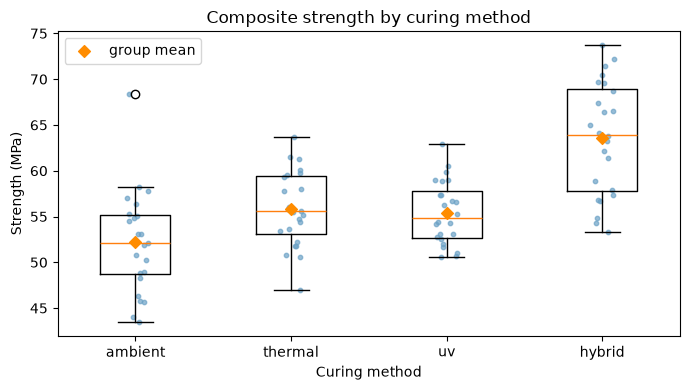

In [5]:
groups = [strengths.loc[strengths["curing_method"] == g, "strength_mpa"] for g in order]

fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot(groups, tick_labels=order)
for i, g in enumerate(groups, start=1):
    ax.scatter(np.full(len(g), i) + np.random.uniform(-0.08, 0.08, len(g)), g, s=10, color="#6CA2C6", alpha=0.7)
ax.scatter(range(1, 5), summary["mean (MPa)"], marker="D", color="#FF8C00", zorder=3, label="group mean")
ax.set_xlabel("Curing method")
ax.set_ylabel("Strength (MPa)")
ax.set_title("Composite strength by curing method")
ax.legend()
plt.tight_layout()
plt.show()

Every method has 24 specimens.

**Differences between the methods:** hybrid gives the strongest specimens on average (63.6 MPa). Ambient is the weakest (52.2 MPa). Thermal (55.8 MPa) and uv (55.4 MPa) are in between and almost the same.

**Differences inside each method:** specimens with the same method are not all equally strong. The standard deviation (how much the values typically differ from their group average) goes from 3.4 MPa for uv to 6.2 MPa for hybrid. Because of this the boxes overlap quite a lot, except hybrid, which sits clearly higher than the others. One ambient specimen (68.4 MPa) is much stronger than the rest of its group.

**c.** State the one-way ANOVA hypotheses. Explain why a collection of unadjusted pairwise t-tests is a poor default.

ANOVA (analysis of variance) is a test that checks if several groups have the same average.

- H0: all four methods give the same average strength.
- H1: at least one method gives a different average strength.

We use a 5% significance level (alpha = 0.05).

**Why not just compare each pair with a t-test?** With 4 methods there are 6 pairs to compare. Every t-test has a 5% risk of finding a difference that is not really there. If we do 6 tests, these risks add up, and the chance of at least one false finding becomes about 26% (1 - 0.95^6). ANOVA does one single test for all groups at once, so the risk stays at 5%.

**d.** Fit the classical one-way model and produce an ANOVA table. Report sums of squares, degrees of freedom, mean squares, F, and p, and explain what the F ratio compares.

In [6]:
model = ols("strength_mpa ~ C(curing_method)", data=strengths).fit()
tbl = anova_lm(model, typ=2)
tbl["mean_sq"] = tbl["sum_sq"] / tbl["df"]
tbl = tbl[["sum_sq", "df", "mean_sq", "F", "PR(>F)"]]
display(tbl)

ss_between = tbl.loc["C(curing_method)", "sum_sq"]
ss_within = tbl.loc["Residual", "sum_sq"]
print(f"SS total = {ss_between + ss_within:.2f}")
print(f"F = {tbl.loc['C(curing_method)', 'F']:.2f}, p = {tbl.loc['C(curing_method)', 'PR(>F)']:.3g}")

,sum_sq,df,mean_sq,F,PR(>F)
C(curing_method),1682.080428,3.0,560.693476,22.942315,3.554955e-11
Residual,2248.412996,92.0,24.439272,NaN,NaN


SS total = 3930.49
F = 22.94, p = 3.55e-11


The ANOVA splits the total variation in strength into two parts:
- **Between groups:** how far the four group averages are from the overall average. This is the part that comes from the curing method.
- **Within groups:** how far each specimen is from its own group average. This is the random variation between specimens (noise).

| Source | Sum of squares (SS) | df | Mean square (MS) | F | p |
|---|---|---|---|---|---|
| Between groups (curing method) | 1682.1 | 3 | 560.7 | 22.94 | 3.6e-11 |
| Within groups (residual) | 2248.4 | 92 | 24.4 | | |
| Total | 3930.5 | 95 | | | |

- **SS (sum of squares):** the squared distances added up. A bigger number means more variation.
- **df (degrees of freedom):** between = number of groups - 1 = 3. Within = number of specimens - number of groups = 96 - 4 = 92.
- **MS (mean square):** SS / df, so a kind of average variation per degree of freedom.

**F** = MS between / MS within = 560.7 / 24.4 = 22.9. It compares how different the methods are with how much specimens normally vary. If the method did not matter, F would be around 1. Here the differences between the methods are about 23 times bigger than what random variation alone would give.

**p = 3.6e-11** (0.000000000036). This is the chance of getting an F this large if all four methods really had the same average. It is far below 0.05, so we reject H0: at least one curing method gives a different average strength. Which methods differ is checked in Part 2.

# Part 2 - Diagnostics, post-hoc comparisons, and magnitude

**a.** Diagnose independence from the study description and inspect within-group errors using group spreads, residual-versus-fitted, and a QQ-plot of residuals. Explain why the pooled raw response is not the correct normality diagnostic.

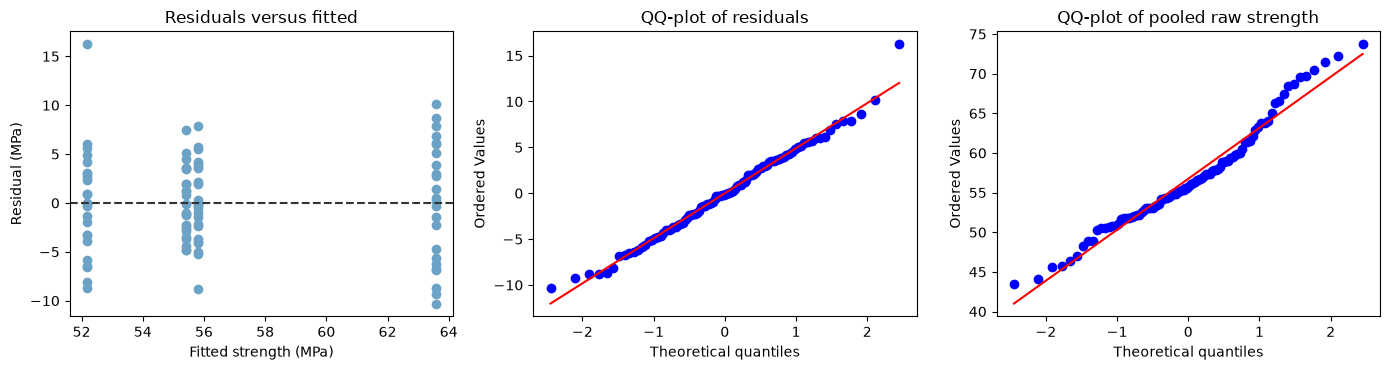

group sds (MPa):
 curing_method
ambient    5.55
thermal    4.09
uv         3.44
hybrid     6.20
Name: sd (MPa), dtype: float64
pooled sd = 4.94 MPa
largest residual = 16.23 MPa (specimen 13)


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].scatter(model.fittedvalues, model.resid, color="#6CA2C6")
axes[0].axhline(0, color="0.2", linestyle="--")
axes[0].set_xlabel("Fitted strength (MPa)")
axes[0].set_ylabel("Residual (MPa)")
axes[0].set_title("Residuals versus fitted")
probplot(model.resid, dist="norm", plot=axes[1])
axes[1].set_title("QQ-plot of residuals")
probplot(strengths["strength_mpa"], dist="norm", plot=axes[2])
axes[2].set_title("QQ-plot of pooled raw strength")
plt.tight_layout()
plt.show()

print("group sds (MPa):\n", summary["sd (MPa)"].round(2))
print(f"pooled sd = {np.sqrt(model.mse_resid):.2f} MPa")
print(f"largest residual = {model.resid.max():.2f} MPa (specimen {strengths.loc[model.resid.idxmax(), 'specimen_id']})")

**Independence:** no plot can show this. We can only judge it from how the study was done. The description says the specimens are independent. That only is true if they were not made from the same batch of material or tested in groups (for example all hybrid specimens on the same day). We don't know this, so we have to assume it.

**Within-group errors:** a residual is how far a specimen is from its own group average.
- **Group spreads:** the sd goes from 3.4 MPa (uv) to 6.2 MPa (hybrid). The largest/smallest ratio is 1.80 (Part 1b), so it is under the usual rule of thumb of 2.
- **Residuals vs fitted:** each group is a vertical band around 0. Hybrid (fitted ≈ 63.6) and ambient (≈ 52.2) are a bit wider than thermal and uv, but there is no strong funnel shape.
- **QQ-plot of residuals:** the points follow the line well, so the errors look close to normal. The one clear exception is specimen 13 (ambient, 68.4 MPa). Its residual is +16.2 MPa, about 3.3 times the pooled sd of 4.94 MPa, and it also makes the ambient sd bigger. It should be checked (test log, defects), not just deleted.

**Why not the pooled raw strength?** ANOVA assumes the errors inside each group are normal, not all 96 strengths together. The groups have different averages, so pooling them mixes four shifted distributions. The third plot shows this: the raw values bend away from the line at the top because of the high hybrid group. That bend comes from the difference between the groups, not from the errors.

**b.** Decide whether the classical common-variance model is credible. Also run Welch's one-way ANOVA as a sensitivity analysis and explain why it is not paired automatically with ordinary Tukey HSD.

In [8]:
welch = anova_oneway(strengths["strength_mpa"], groups=strengths["curing_method"], use_var="unequal")
print(f"Welch: F = {welch.statistic:.2f}, df = (3, {welch.df_denom:.1f}), p = {welch.pvalue:.2g}")

Welch: F = 15.57, df = (3, 49.9), p = 2.8e-07


The classical model (one common sd for all groups) looks credible. All groups have 24 specimens, and with equal group sizes the F-test is not very sensitive to some difference in spread. The sd ratio is under 2 and the residuals look normal apart from specimen 13.

As a sensitivity check, Welch's ANOVA does not assume equal spreads. It gives F = 15.57 on (3, 49.9) df, p = 2.8e-07. The classical test gave F = 22.94, p = 3.6e-11. Both reject H0, so the conclusion does not depend on the equal-variance assumption.

Why not Welch + Tukey?:

Tukey HSD uses the pooled MS within (one common sd = 4.94 MPa) for every pair, which is exactly the equal-variance assumption Welch drops. A method that fits Welch would be Games-Howell, but it is not in statsmodels or scipy. Here the classical model is credible, so we use Tukey together with the classical ANOVA.

**c.** Calculate η² = SS_between / SS_total and interpret it as a descriptive fraction of observed total squared variation, not causation.

In [9]:
eta2 = ss_between / (ss_between + ss_within)
print(f"eta-squared = {ss_between:.1f} / {ss_between + ss_within:.1f} = {eta2:.3f}")

eta-squared = 1682.1 / 3930.5 = 0.428


η² = 0.428, so about 43% of the total squared variation in strength in our sample is between the four method averages. The other 57% is variation between specimens with the same method.

This only describes our sample. It does not mean the curing method causes 43% of the strength. η² would also change with other methods or with more or less noise between specimens.

**d.** If the classical omnibus test is relevant and significant, perform Tukey HSD. Report simultaneous pairwise intervals and adjusted p-values and identify which curing methods are distinguishable. Do not treat a non-significant pair as proof of equal means.

In [10]:
tukey = pairwise_tukeyhsd(strengths["strength_mpa"], strengths["curing_method"], alpha=0.05)
print(tukey.summary())

  Multiple Comparison of Means - Tukey HSD, FWER=0.05  
 group1  group2 meandiff p-adj   lower    upper  reject
-------------------------------------------------------
ambient  hybrid  11.3937    0.0   7.6596 15.1279   True
ambient thermal     3.64 0.0589  -0.0942  7.3742  False
ambient      uv   3.2383 0.1129  -0.4958  6.9725  False
 hybrid thermal  -7.7538    0.0 -11.4879 -4.0196   True
 hybrid      uv  -8.1554    0.0 -11.8896 -4.4213   True
thermal      uv  -0.4017 0.9922  -4.1358  3.3325  False
-------------------------------------------------------


The classical ANOVA is credible and significant, so we use Tukey HSD. The intervals are simultaneous 95% intervals, meaning all 6 hold together with 95% confidence, and the p-values are adjusted for doing 6 comparisons.

| Pair | Difference (MPa) | 95% interval | adj. p |
|---|---|---|---|
| hybrid − ambient | +11.39 | [7.66, 15.13] | < 0.001 |
| hybrid − thermal | +7.75 | [4.02, 11.49] | < 0.001 |
| hybrid − uv | +8.16 | [4.42, 11.89] | < 0.001 |
| thermal − ambient | +3.64 | [−0.09, 7.37] | 0.059 |
| uv − ambient | +3.24 | [−0.50, 6.97] | 0.113 |
| thermal − uv | +0.40 | [−3.33, 4.14] | 0.992 |

Only hybrid can be told apart: it is stronger than all three other methods. Ambient, thermal and uv cannot be separated. That does not mean they are equal. For example, thermal − ambient goes up to 7.4 MPa, so a real difference of that size is still possible. We just don't have enough evidence for it.

**e.** Write a recommendation in MPa that distinguishes the global question, specific pairwise differences, practical importance, and design limitations.

- **Global question:** the curing methods do not all give the same average strength (classical and Welch ANOVA both p < 0.001).
- **Pairwise:** hybrid gives about 8–11 MPa higher average strength than the other three methods (at least 4–8 MPa from the lower interval bounds). Between ambient, thermal and uv the data cannot pick a better method.
- **Practical importance:** 8–11 MPa on a base of about 52–56 MPa is roughly 14–22% stronger, which is large compared with the normal specimen-to-specimen sd of about 5 MPa. Whether it is worth it depends on the required design strength and the extra cost of hybrid curing. Hybrid also has the largest spread (sd 6.2 MPa), so its weakest specimens (around 53 MPa) are no stronger than a typical thermal or uv specimen. If the design is based on minimum strength, the gain is smaller than the average suggests.
- **Limitations:** the result only covers these four methods and these conditions. We can only say the method *causes* the difference if specimens were randomly assigned and not made, cured or tested in batches (see Part 1a). Specimen 13 should be checked. With 24 specimens per group, a new production run could give somewhat different numbers.
- **Diagnostics:** residuals look close to normal and the group sds are similar enough (ratio 1.80) for the classical model. Welch's ANOVA gives the same conclusion, so the result does not depend on equal variances.

# Part 3 — Pump flow and energy use

a. Identify the population, observational unit, response, predictor, and observed predictor range. Create a scatterplot and discuss whether a linear conditional-mean model is plausible before fitting it.

In [ ]:
# Code Here

// Discussion for a. here

b. Fit an intercept model with statsmodels. Report and interpret $\hat{\beta}_0$, $\hat{\beta}_1$, residual standard deviation, Pearson correlation $r$, and $R^2$. Include units and discuss whether the intercept has a useful engineering interpretation.


In [ ]:
# Code here

// Discussion for b. here

c. Verify that $R^2 = r^2$ for this simple intercept model. Explain what correlation and $R^2$ measure and what they do not establish.


In [ ]:
# Code here

// Discussion for c. here

d. Test $H_0 : \beta_1 = 0$ against a two-sided alternative and report the slope estimate, standard error, 95% interval, $t$, degrees of freedom, and $p$-value. State the conclusion as an association, not automatically as causation.

In [ ]:
# Code here

// Discussion for d. here

# Part 4 — Regression diagnostics and prediction

a. Create residual-versus-fitted, residual-versus-run-order, and normal QQ-plots. Discuss linearity, constant spread, unusual observations, normal-error approximation, and what the plots cannot establish about independence or sampling.

In [ ]:
# Code here

// Discussion for a. here

b. Calculate leverage and Cook's distance. Identify the most influential run, investigate it rather than deleting it automatically, and explain what operational information you would seek.

In [ ]:
# Code here

// Discussion for b. here

c. At $x_0 = 70$ L/min, report the fitted mean energy, a 95% confidence interval for mean energy, and a 95% prediction interval for one new run. Explain why the prediction interval is wider.


In [ ]:
# Code here

// Discussion for c. here

d. Explain why using this fitted line at 10 or 120 L/min would be extrapolation. State what evidence would be needed before extending the relationship outside the observed range.


In [ ]:
# Code here

// Discussion for d. here

e. Give a practical conclusion that includes slope in kWh per L/min, uncertainty, residual variation, $R^2$, prediction uncertainty, and study-design limitations.

In [ ]:
# Code here

// Discussion for e. here